# 02 · Curvas de Kaplan-Meier e riscos competitivos

Este notebook responde **qual a probabilidade de um contrato chegar a cada mês sem default**, para a carteira toda e por perfil (prazo, renda, moradia e grade).

Dois estimadores, cada um com seu papel:

| Estimador | Pergunta que responde | Uso |
|---|---|---|
| **Kaplan-Meier** (pré-pagamento = censura) | Qual seria a sobrevivência se ninguém quitasse antes? | Comparar o *ritmo* de default entre grupos. O log-rank testa exatamente isso. |
| **Aalen-Johansen** (riscos competitivos) | Qual fração dos contratos de fato termina em default até o mês *t*? | Probabilidade real, que é o que entra na provisão (PCLD). |

Como o tempo é medido em meses inteiros, os dois estimadores saem exatos de uma tábua de vida mensal (`time_to_default.survival.life_table`), conferida contra o `lifelines` nos testes.

Como "tipo de garantia" não existe nesta base (os empréstimos do LendingClub são pessoais e sem garantia), o **tipo de moradia** entra no lugar como o indicador mais próximo de patrimônio.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from time_to_default.features import PROCESSED_PATH
from time_to_default.plotting import (BLUE, GRAY, ORANGE, SERIES, ordinal_colors, percent_axis,
                                      plot_curves_by_term, savefig, set_style)
from time_to_default.reporting import update_metrics
from time_to_default.survival import life_table, life_tables_by, logrank_by, summary_at

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

data = pd.read_parquet(PROCESSED_PATH)
TERMS = (36, 60)
by_term = {t: data[data["term_months"] == t] for t in TERMS}
print(f"{len(data):,} contratos")

2,064,692 contratos


## 1. A carteira toda: por que o Kaplan-Meier sozinho engana

O KM trata quem quitou antes como alguém que *continuaria* exposto ao default. Como quase 40% dos contratos são quitados antecipadamente, `1 − KM` superestima bastante a fração que de fato inadimple.

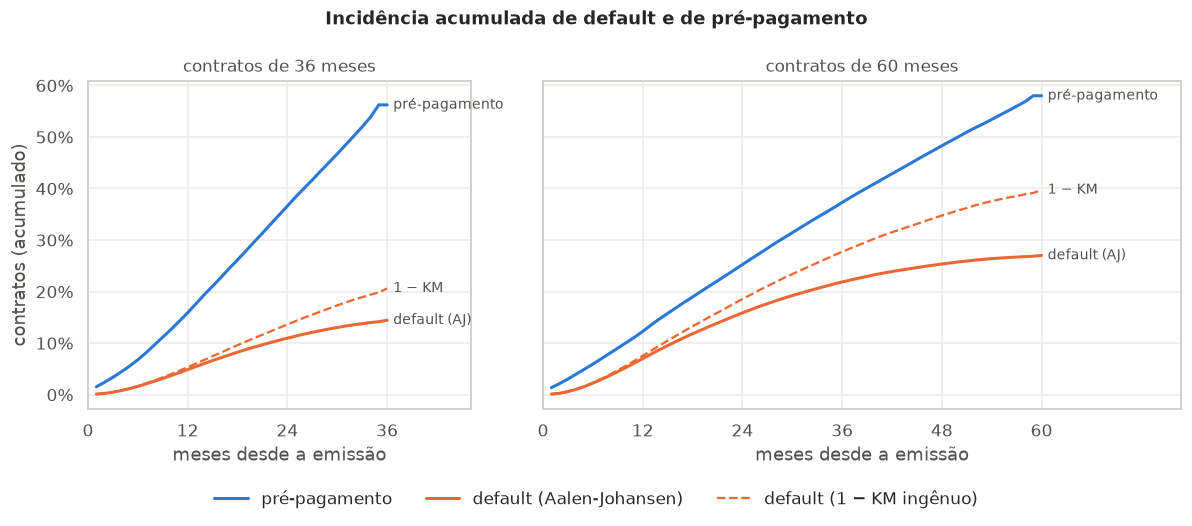

In [2]:
overall = {t: life_table(s["duration"], s["event"]) for t, s in by_term.items()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True, gridspec_kw={"width_ratios": TERMS})
for ax, (term, tab) in zip(axes, overall.items()):
    series = [
        ("cif_prepay", BLUE, "-", "pré-pagamento"),
        ("cif_default", ORANGE, "-", "default (Aalen-Johansen)"),
    ]
    for col, color, ls, label in series:
        ax.plot(tab.index, tab[col], color=color, ls=ls, label=label)
    ax.plot(tab.index, 1 - tab["km_default"], color=ORANGE, ls="--", lw=1.5, label="default (1 − KM ingênuo)")
    end = tab.iloc[-1]
    for y, text in [(end["cif_prepay"], "pré-pagamento"), (end["cif_default"], "default (AJ)"),
                    (1 - end["km_default"], "1 − KM")]:
        ax.annotate(text, (term, y), xytext=(4, 0), textcoords="offset points", va="center",
                    fontsize=9, color=GRAY)
    ax.set_title(f"contratos de {term} meses", fontsize=11, fontweight="normal", color=GRAY)
    ax.set_xticks(range(0, term + 1, 12))
    ax.set_xlim(0, term * 1.28)
    ax.set_xlabel("meses desde a emissão")
    percent_axis(ax)
axes[0].set_ylabel("contratos (acumulado)")
fig.suptitle("Incidência acumulada de default e de pré-pagamento", fontweight="bold", fontsize=12)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.08), frameon=False)
fig.tight_layout()
savefig(fig, "competing_risks_overall")
plt.show()

In [3]:
horizons = pd.DataFrame({
    f"{term}m": {
        "default em 12m (AJ)": tab.loc[12, "cif_default"],
        "default no prazo (AJ)": tab.loc[term, "cif_default"],
        "default no prazo (1 − KM)": 1 - tab.loc[term, "km_default"],
        "superestimação do KM": (1 - tab.loc[term, "km_default"]) / tab.loc[term, "cif_default"] - 1,
        "pré-pagamento no prazo (AJ)": tab.loc[term, "cif_prepay"],
    }
    for term, tab in overall.items()
})
horizons

,36m,60m
default em 12m (AJ),0.0487,0.0700
default no prazo (AJ),0.1444,0.2700
default no prazo (1 − KM),0.2060,0.3970
superestimação do KM,0.4268,0.4702
pré-pagamento no prazo (AJ),0.5623,0.5799


## 2. Kaplan-Meier por prazo

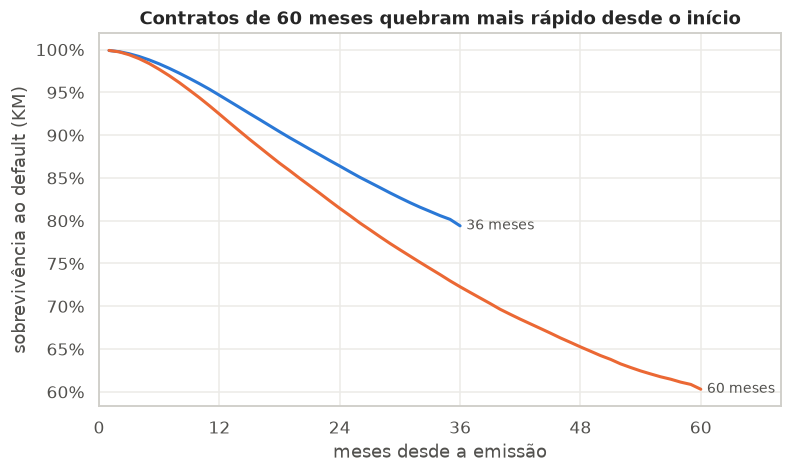

In [4]:
km_term = {"todos": {f"{t} meses": tab for t, tab in overall.items()}}
fig, ax = plt.subplots(figsize=(8, 4.4))
for (label, tab), color in zip(km_term["todos"].items(), SERIES):
    ax.plot(tab.index, tab["km_default"], color=color, label=label)
    ax.annotate(label, (tab.index[-1], tab["km_default"].iloc[-1]), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=9, color=GRAY)
ax.set_xticks(range(0, 61, 12))
ax.set_xlim(0, 68)
ax.set_xlabel("meses desde a emissão")
ax.set_ylabel("sobrevivência ao default (KM)")
ax.set_title("Contratos de 60 meses quebram mais rápido desde o início")
percent_axis(ax)
savefig(fig, "km_by_term")
plt.show()

## 3. Kaplan-Meier por faixa de renda (US$ por ano)

Daqui em diante os grupos são comparados **dentro de cada prazo**. Contratos de 60 meses têm valores e juros maiores e tomadores de renda mais alta, então misturar os prazos confundiria o efeito da renda com o do prazo.

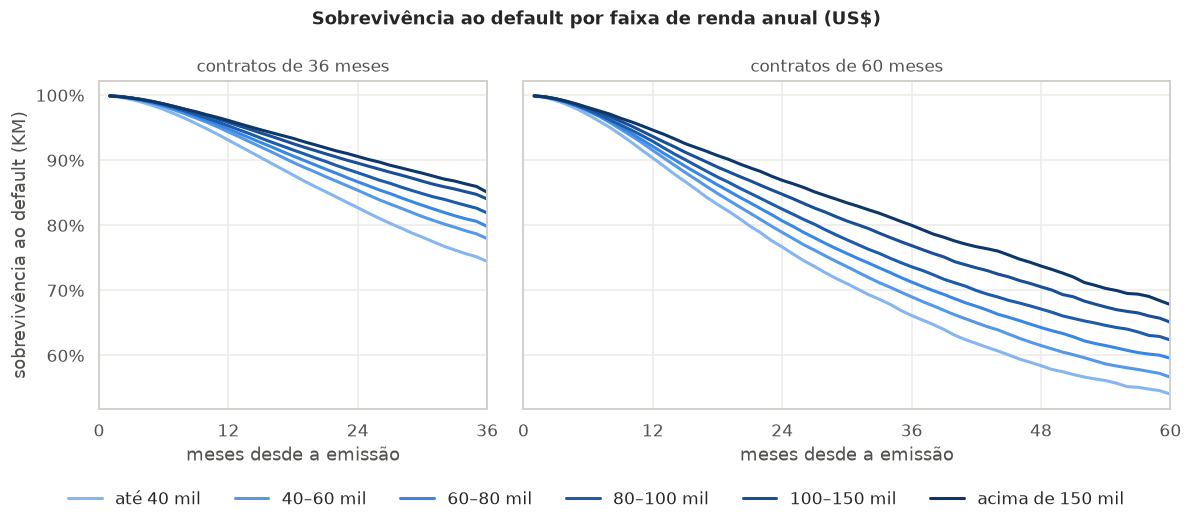

,36m · contratos,36m · KM 12m,36m · AJ 12m,36m · KM 24m,36m · AJ 24m,36m · KM 36m,36m · AJ 36m,60m · contratos,60m · KM 12m,60m · AJ 12m,60m · KM 24m,60m · AJ 24m,60m · KM 60m,60m · AJ 60m
grupo,,,,,,,,,,,,,,
até 40 mil,263673,0.0691,0.0641,0.1729,0.1448,0.2557,0.1911,40206,0.0967,0.0914,0.2334,0.2078,0.4595,0.3471
40–60 mil,392625,0.0565,0.0517,0.1462,0.1181,0.2205,0.1557,135584,0.0849,0.0792,0.2109,0.1831,0.4335,0.3082
60–80 mil,324978,0.0518,0.0471,0.1332,0.1059,0.2018,0.1389,145453,0.0788,0.0730,0.1932,0.1649,0.4044,0.2756
80–100 mil,200917,0.0470,0.0426,0.1192,0.0943,0.1810,0.1232,101692,0.0710,0.0657,0.1751,0.1483,0.3764,0.2492
100–150 mil,204811,0.0417,0.0378,0.1044,0.0828,0.1596,0.1082,107840,0.0635,0.0586,0.1523,0.1287,0.3490,0.2237
acima de 150 mil,99598,0.0388,0.0355,0.0942,0.0761,0.1492,0.1025,47315,0.0537,0.0496,0.1309,0.1105,0.3219,0.2029


In [5]:
def by_group(group):
    return {t: life_tables_by(s, group) for t, s in by_term.items()}


def horizon_table(tables):
    parts = [summary_at(tabs, months=(12, 24, t)).add_prefix(f"{t}m · ") for t, tabs in tables.items()]
    return pd.concat(parts, axis=1)


income = by_group("income_band")
fig = plot_curves_by_term(income, "km_default", ordinal_colors(6),
                          "Sobrevivência ao default por faixa de renda anual (US$)", "sobrevivência ao default (KM)")
savefig(fig, "km_by_income")
plt.show()
horizon_table(income)

## 4. Kaplan-Meier por tipo de moradia

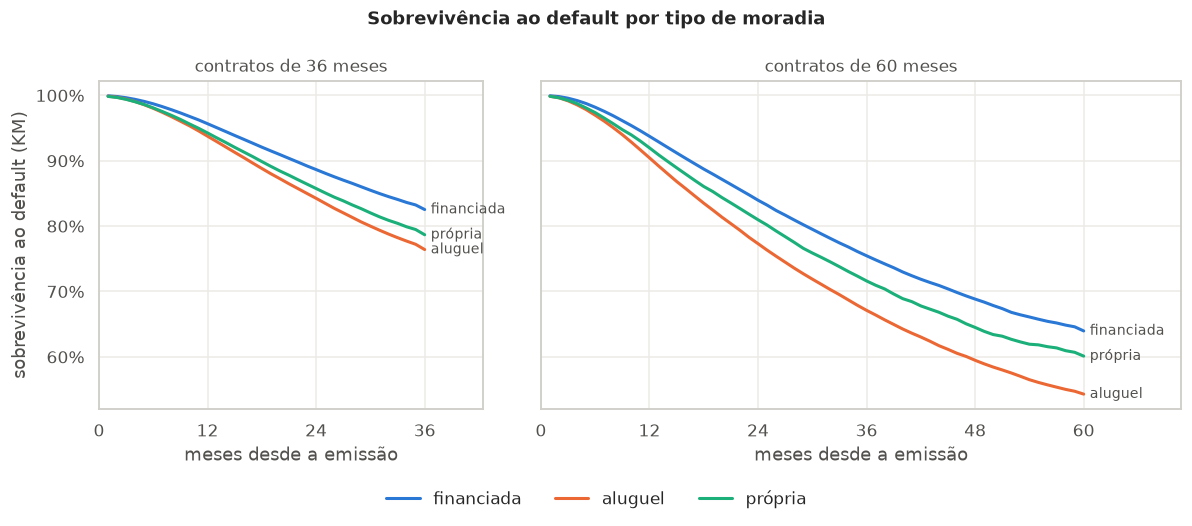

,36m · contratos,36m · KM 12m,36m · AJ 12m,36m · KM 24m,36m · AJ 24m,36m · KM 36m,36m · AJ 36m,60m · contratos,60m · KM 12m,60m · AJ 12m,60m · KM 24m,60m · AJ 24m,60m · KM 60m,60m · AJ 60m
grupo,,,,,,,,,,,,,,
financiada,669895,0.0434,0.0393,0.1136,0.0894,0.1747,0.1181,326980,0.0627,0.0578,0.1604,0.1353,0.3604,0.2352
aluguel,642277,0.0625,0.0578,0.1575,0.1297,0.2359,0.1708,192232,0.0957,0.0897,0.2269,0.1991,0.4570,0.3310
própria,174430,0.0575,0.0524,0.1425,0.1150,0.2133,0.1515,58878,0.0804,0.0740,0.1903,0.1616,0.3989,0.2739


In [6]:
home = by_group("home")
fig = plot_curves_by_term(home, "km_default", SERIES[:3],
                          "Sobrevivência ao default por tipo de moradia", "sobrevivência ao default (KM)",
                          direct_labels=True)
savefig(fig, "km_by_home")
plt.show()
horizon_table(home)

## 5. Kaplan-Meier por grade de risco

O grade (A a G) é a classificação de risco da própria LendingClub na concessão. Ele serve de referência: se o score de concessão funciona, as curvas precisam se separar em ordem.

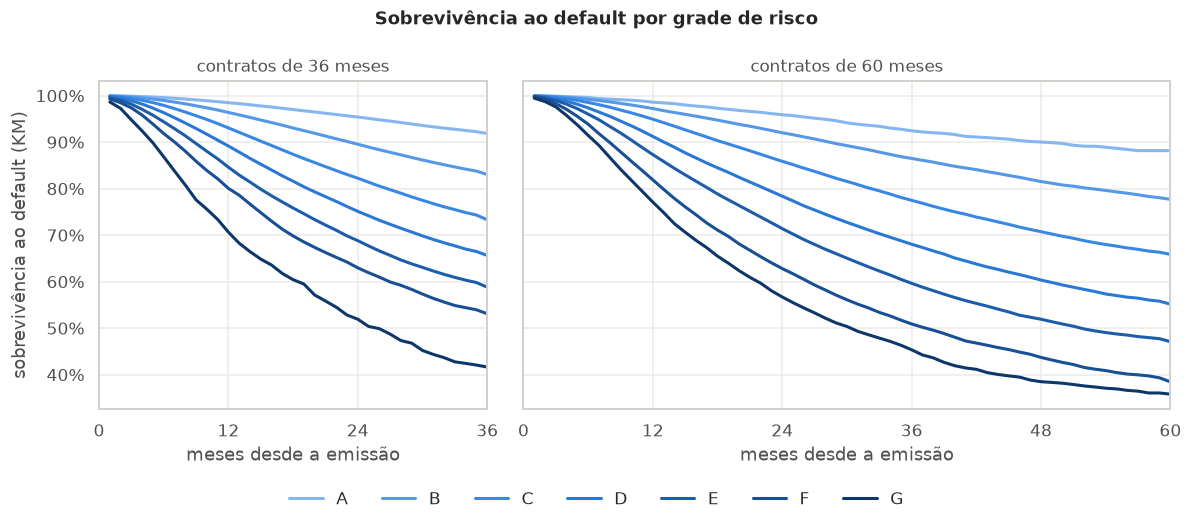

,36m · contratos,36m · KM 12m,36m · AJ 12m,36m · KM 24m,36m · AJ 24m,36m · KM 36m,36m · AJ 36m,60m · contratos,60m · KM 12m,60m · AJ 12m,60m · KM 24m,60m · AJ 24m,60m · KM 60m,60m · AJ 60m
grupo,,,,,,,,,,,,,,
A,369776,0.0152,0.0140,0.0461,0.0370,0.0817,0.0545,19418,0.0142,0.0134,0.0411,0.0360,0.1184,0.0784
B,500361,0.0362,0.0332,0.1046,0.0836,0.1696,0.1159,108820,0.0278,0.0262,0.0800,0.0692,0.2231,0.1439
C,391171,0.0696,0.0631,0.1777,0.1419,0.2671,0.1862,203859,0.0508,0.0474,0.1414,0.1211,0.3415,0.2266
D,169877,0.1085,0.0977,0.2489,0.1993,0.3438,0.2470,125527,0.0879,0.0814,0.2163,0.1845,0.4486,0.3081
E,45304,0.1540,0.1381,0.3120,0.2524,0.4120,0.3035,79762,0.1270,0.1156,0.2861,0.2396,0.5292,0.3673
F,8287,0.1995,0.1786,0.3704,0.3025,0.4691,0.3547,31305,0.1813,0.1630,0.3720,0.3078,0.6156,0.4293
G,1826,0.2937,0.2587,0.4809,0.3884,0.5838,0.4405,9399,0.2291,0.2025,0.4331,0.3522,0.6420,0.4559


In [7]:
grade = by_group("grade")
fig = plot_curves_by_term(grade, "km_default", ordinal_colors(7),
                          "Sobrevivência ao default por grade de risco", "sobrevivência ao default (KM)")
savefig(fig, "km_by_grade")
plt.show()
horizon_table(grade)

## 6. Testes log-rank

O log-rank testa se o hazard de default é o mesmo em todos os grupos. Com 1,5 milhão de contratos, qualquer diferença minúscula dá p-valor zero, então **o p-valor aqui só confirma o óbvio**. O que importa é o tamanho da diferença nas tabelas acima e a estatística qui-quadrado, que serve para comparar a força de separação entre as variáveis.

In [8]:
tests = pd.DataFrame([
    logrank_by(s, g).rename(f"{g} · {t}m")
    for g in ["income_band", "home", "grade"] for t, s in by_term.items()
] + [logrank_by(data, "term_months").rename("prazo · todos")])
tests["qui² por grau de liberdade"] = tests["estatística"] / tests["graus de liberdade"]
tests

,estatística,graus de liberdade,p-valor,qui² por grau de liberdade
income_band · 36m,"5,289.3731",5.0000,0.0000,"1,057.8746"
income_band · 60m,"2,372.5209",5.0000,0.0000,474.5042
home · 36m,"4,274.8269",2.0000,0.0000,"2,137.4134"
home · 60m,"3,026.3272",2.0000,0.0000,"1,513.1636"
grade · 36m,"56,030.1301",6.0000,0.0000,"9,338.3550"
grade · 60m,"26,466.8728",6.0000,0.0000,"4,411.1455"
prazo · todos,"6,794.9533",1.0000,0.0000,"6,794.9533"


## Leitura dos resultados

- **Riscos competitivos mudam o número.** Nos contratos de 36 meses, `1 − KM` aponta 20,6% de default até o fim do prazo, mas a fração que de fato inadimple é 14,4%. O KM superestima em 43% (47% nos contratos de 60 meses: 39,7% contra 27,0%), porque ignora que mais da metade da carteira quita antes. Para PCLD, o número certo é o do Aalen-Johansen.
- **O prazo pesa muito.** Os contratos de 60 meses têm hazard de default mais alto desde os primeiros meses, e não só por durarem mais.
- **A renda tem efeito monotônico.** Cada faixa acima tem menos default, e a de até US$ 40 mil chega a quase o dobro da faixa acima de US$ 150 mil.
- **Na moradia, financiada < própria < aluguel.** Quem tem imóvel financiado já passou por uma análise de crédito hipotecário, o que explica ser o grupo de menor risco, à frente de quem tem imóvel quitado.
- **O grade separa muito mais do que qualquer variável isolada**, com a maior estatística log-rank por grau de liberdade. Faz sentido, porque o grade já resume renda, histórico e o próprio juro.

**Limitações das curvas:**
1. São univariadas. Renda, moradia e grade são correlacionadas, então parte do "efeito da renda" é efeito do grade. Separar esses efeitos é o papel do Cox (notebook 04).
2. Juntam safras diferentes. O fim das curvas (meses 30 a 60) vem só das safras antigas, porque as recentes ainda não chegaram lá. Se o risco mudou entre safras, o formato da curva mistura as duas coisas. Isso é revisitado na validação fora do tempo (notebook 05).

In [9]:
def at(tab, m, col):
    return round(float(tab.loc[m, col]), 4)

update_metrics("kaplan_meier", {
    f"term_{t}": {
        "cif_default_12m": at(tab, 12, "cif_default"),
        "cif_default_term": at(tab, t, "cif_default"),
        "naive_km_default_term": round(1 - float(tab.loc[t, "km_default"]), 4),
        "cif_prepay_term": at(tab, t, "cif_prepay"),
    }
    for t, tab in overall.items()
} | {
    "by_group_36m_cif_default_36m": {
        g: {str(k): at(v, 36, "cif_default") for k, v in tabs[36].items()}
        for g, tabs in {"income_band": income, "home": home, "grade": grade}.items()
    },
    "logrank_chi2": tests["estatística"].round(1).to_dict(),
})

{'data': {'raw_loans': 2260668,
  'loans': 2064692,
  'snapshot': '2019-03',
  'observation_end': '2018-11',
  'funnel': [{'etapa': 'base bruta', 'contratos': 2260668, 'removidos': 0},
   {'etapa': 'dentro da política de crédito',
    'contratos': 2257919,
    'removidos': 2749},
   {'etapa': 'pedido individual', 'contratos': 2137209, 'removidos': 120710},
   {'etapa': 'moradia própria, financiada ou aluguel',
    'contratos': 2136024,
    'removidos': 1185},
   {'etapa': 'renda anual positiva', 'contratos': 2136024, 'removidos': 0},
   {'etapa': 'emitido antes do fim da observação',
    'contratos': 2064692,
    'removidos': 71332}],
  'event_share': {'censurado': 0.5047,
   'pré-pagamento': 0.3715,
   'default': 0.1239},
  'term_36_share': 0.72},
 'kaplan_meier': {'term_36': {'cif_default_12m': 0.0487,
   'cif_default_term': 0.1444,
   'naive_km_default_term': 0.206,
   'cif_prepay_term': 0.5623},
  'term_60': {'cif_default_12m': 0.07,
   'cif_default_term': 0.27,
   'naive_km_defaul